# Aircast Phase 1 — reproducible classical PM2.5 forecasting

Run every cell in order in Google Colab or the project environment. The embedded source
snapshot is generated by `scripts/build_phase1_notebook.py` and verified before extraction.
A fresh runtime trains the full classical experiment. A checkout with completed results
inspects and verifies them; set `RUN_FULL_TRAINING=True` to train a separate new run.
No completed run is overwritten. Targets are one hour ahead; timestamps use Beijing local time.

In [1]:
import base64, io, json, os, sys, zipfile
from hashlib import sha256
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if (Path.cwd() / 'src/air_prediction').is_dir():
    ROOT = Path.cwd()
elif (Path.cwd().parent / 'src/air_prediction').is_dir():
    ROOT = Path.cwd().parent
else:
    ROOT = Path('/content/air_prediction') if IN_COLAB else Path.cwd() / 'air_prediction'

SOURCE_BUNDLE = '...'
SOURCE_BUNDLE_SHA256 = 'e8ac2f679897cad89993ab3608f6db89193011cb80fe2fb7f3a2cf624235e672'
SOURCE_FILES = {'pyproject.toml': '3d00ec5dd0c0f08fe91ed282d9a2da641c818f72b94f5f2cd424d0146e1d7868', 'requirements.txt': 'f6522a3d253d9cee60ca6422c69e7b4c335ee975b2e677a515211820a2dbbe53', 'requirements-phase1.txt': '2a14a8633b1b3bfe05d74b7c920bcb9e8af5ae7dd7526743812c592841ab0557', 'LICENSE': 'e2cc2416866c2512dddb8cf4052dbf1b95610a028d9aae1cd6936c96491a3528', 'configs/phase1.toml': '50d16432bf840dea6b4be31de173d74e7d9a4ade34b0a2ef6ba0f11ab29df10a', 'configs/demo.toml': '7d2a1f7dbc94f9b69e10e918747b557135242cc98f1a3322bf0d5999c7bf1be9', 'data/README.md': '3343f117cce21bc207151f563ac51f47d02876076a33c5307d9290dbee89d132', 'docs/methodology.md': '8a0b85aa16667fe864f5402e65516f4091d462a19dad1208edaeaa92d748bde5', 'docs/phase1_checklist.md': 'e2d9999058d3325ba5333aaadd8753ef582b9cce9d5c7a5ce9ae5e34d3b3551d', 'tests/conftest.py': 'fb423199ad33600b89bb4912a1d67164bcad9ce9b70b2195cc06de171ba4a73f', 'tests/test_forecasting.py': '7ea79d7051614b9bc9c646e68e95981086589a37159cc78d5f5915605bd36ec8', 'tests/test_data_and_integration.py': '1b648af07a64a2cd24729559a0a7e394d8728bc4c14613144b486c91966491b1', 'tests/test_eda_notes.py': '5bb57aac9c560b4a99a534cc2368c5007f648abd80d293c8d40851da0f8315a3', 'tests/test_xgboost_optional.py': '77185878b97705b34a295df1ad997ab742101044f03a369ca10391cec4122989', 'src/air_prediction/__init__.py': '2293e94cf966b6d0b07b514b217152b9ed7d4b5921fd428e2fb087b0522a010a', 'src/air_prediction/__main__.py': '6d8b7d7846a845059d7a3107143f11131f63c5511d669b44085b15ec5e3d2279', 'src/air_prediction/cli.py': '1d03ea264025673d4b702816b3895b4bfa73c40f842c92ab58ab4cad6e111ef1', 'src/air_prediction/config.py': 'b30a1ff122439f287167e5d5c76a098d77912d5d2b8909e648954ac7f76b3d69', 'src/air_prediction/data.py': '024f8c62c7cc7b01529f7efcc9b0a8cba4058f2658261c267db364a95f087ba8', 'src/air_prediction/deep_learning.py': 'eb8836d5de6be2e0765ca60745560e15dbcfbc38a9596f8eb17e1bf293540496', 'src/air_prediction/demo.py': '711dca94046382f98902f5506091e58a719ae31bd4b11ef898a0c907a420b824', 'src/air_prediction/eda.py': '283955e44e25e21c76d434ddf34c9078cdd6ee37c840fa9f44200afc20f93043', 'src/air_prediction/experiment.py': '44170084233e8592a8a3c2ff8a24d8506240c6b671ea0c1567af6d6a712a05d2', 'src/air_prediction/features.py': 'ea9277347a6a4508f81c446267663dbdb3577cfcacc19112a9cac50fbc141831', 'src/air_prediction/metrics.py': 'c05874f36b670169b08ad266c95a3b7b022756f9d74cd43834d235beae111bdb', 'src/air_prediction/models.py': '3b13704e78234cbd55ef69f012ecd589ceb109ffc5973a49a27c4817d9c7c300', 'src/air_prediction/phase2.py': 'ca4722ff5bba885f89b98f7f371b4c22e215dd41d05e09ede4fa979ca6f8ff4f', 'src/air_prediction/phase2_research.py': 'd697510d6f52d48aa90cbff8cda77d903d6c472a4873653cda61c1e02587f98b', 'src/air_prediction/predict.py': '0e45a56f932e2bc2331ad4c24eea8d0c24dfbc0f25af590637faf1ad0dfd7bcb', 'src/air_prediction/results.py': '44543efe599b1f4853ea61f9023c31b7a74b0d48b579576863685febf8eadc19', 'src/air_prediction/splits.py': '91e59bf69d2616d9f46dbb13da99ef4765da07d52591985bdeb6482ed08680b1'}
snapshot = base64.b64decode(SOURCE_BUNDLE)
assert sha256(snapshot).hexdigest() == SOURCE_BUNDLE_SHA256
ROOT.mkdir(parents=True, exist_ok=True)
if not (ROOT / 'src/air_prediction').is_dir():
    with zipfile.ZipFile(io.BytesIO(snapshot)) as archive:
        assert set(archive.namelist()) == set(SOURCE_FILES)
        for name, expected in SOURCE_FILES.items():
            content = archive.read(name)
            assert sha256(content).hexdigest() == expected
            target = (ROOT / name).resolve()
            assert target.is_relative_to(ROOT.resolve())
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(content)
for name, expected in SOURCE_FILES.items():
    if name.startswith(('src/', 'configs/')):
        assert sha256((ROOT / name).read_bytes()).hexdigest() == expected, 'Notebook source differs: ' + name
os.chdir(ROOT)
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(key, '1')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
sys.path.insert(0, str(ROOT / 'src'))
print('Source snapshot verified:', SOURCE_BUNDLE_SHA256)
print('Runtime:', sys.version.split()[0], '| Colab:', IN_COLAB)


Source snapshot verified: e8ac2f679897cad89993ab3608f6db89193011cb80fe2fb7f3a2cf624235e672
Runtime: 3.13.5 | Colab: False


**Environment.** Colab installs the recorded classical dependencies automatically.
Locally, run `python -m pip install -r requirements-phase1.txt` first, or enable installation below.
macOS may also require `brew install libomp`. PyTorch is optional for this phase.

In [2]:
import subprocess
INSTALL_DEPENDENCIES = IN_COLAB
if INSTALL_DEPENDENCIES:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', 'requirements-phase1.txt'], check=True)
import numpy as np
import pandas as pd
from air_prediction.config import load_config
from air_prediction.data import FILENAME, download_dataset, load_dataset
from air_prediction.experiment import run_experiment, source_fingerprint
from air_prediction.features import build_features, common_evaluation_mask
from air_prediction.metrics import score_predictions
from air_prediction.predict import predict_latest
try:
    from IPython.display import display, Image as NotebookImage
except ImportError:
    def display(value):
        print(value.to_string() if isinstance(value, (pd.DataFrame, pd.Series)) else value)
    NotebookImage = None
print('NumPy:', np.__version__, '| pandas:', pd.__version__)
print('Forecasting source:', source_fingerprint())


NumPy: 2.1.3 | pandas: 2.2.3
Forecasting source: ba686e2f1da9f2bf60982912d08d0d9d1aa71df1efa48caf288ba52c7dc7eec5


In [3]:
CONFIG = load_config(ROOT / 'configs/phase1.toml')
DATA = ROOT / 'data/raw' / FILENAME
if not DATA.exists():
    download_dataset(DATA)
dataset = load_dataset(DATA)
print(json.dumps(dataset.audit, indent=2))
print('Feature and split configuration:', CONFIG.to_dict())
assert dataset.source != 'synthetic'


{
  "source": "uci381_user_supplied",
  "path": "/Users/prathammalhotra/Desktop/air_pred/data/raw/PRSA_data_2010.1.1-2014.12.31.csv",
  "sha256": "4127f868775e31b3956522adc0ec75af8937dde6a3896e8beed3a376c6d27f1c",
  "input_rows": 43824,
  "hourly_rows": 43824,
  "inserted_missing_hours": 0,
  "input_was_sorted": true,
  "duplicate_timestamps": 0,
  "start": "2010-01-01 00:00:00",
  "end": "2014-12-31 23:00:00",
  "timezone": "Asia/Shanghai (local clock)",
  "missing_by_column": {
    "pm2.5": 2067,
    "DEWP": 0,
    "TEMP": 0,
    "PRES": 0,
    "Iws": 0,
    "Is": 0,
    "Ir": 0,
    "cbwd": 0
  },
  "provenance": {
    "source": "uci381_user_supplied",
    "acquisition": "User-provided local CSV; no download performed by this run",
    "original_filename": "PRSA_data_2010.1.1-2014.12.31.csv",
    "dataset_page": "https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data",
    "doi": "10.24432/C5JS49",
    "license": "CC BY 4.0",
    "sha256": "4127f868775e31b3956522adc0ec75af8937dd

**Train or inspect.** A new run includes all three XGBoost candidates, Ridge, both naive
references, validation ablations, quarterly backtests and final deployment refits.
The source snapshot preserves the original experimental settings. Reproduction of an
already-inspected comparison year does not provide a fresh blind evaluation.

In [4]:
from datetime import datetime, timezone
RUN_FULL_TRAINING = os.environ.get('AIRCAST_PHASE1_RETRAIN', '0') == '1'
RUN = ROOT / 'artifacts/phase1'
required_evidence = (
    'run_manifest.json', 'selection.json', 'predictions.csv', 'metrics.csv', 'fold_metrics.csv',
    'fold_audit.json', 'validation_candidates.csv', 'validation_ablation.csv',
    'errors_by_pollution_regime.csv', 'RESULTS.md', 'xgboost.joblib', 'ridge.joblib',
    'eda/missingness.csv', 'eda/descriptive_statistics.csv', 'eda/autocorrelation.csv', 'eda/EDA_NOTES.md',
    'eda/timeline_missingness.png', 'eda/distribution_seasonality.png', 'eda/correlation_autocorrelation.png',
    'figures/model_comparison.png', 'figures/forecast_last_week.png', 'figures/residual_diagnostics.png',
)
missing_evidence = [name for name in required_evidence if not (RUN / name).is_file()]
if RUN_FULL_TRAINING or missing_evidence:
    if missing_evidence:
        print('A complete Phase 1 evidence set is unavailable; training into a new directory.')
    RUN = ROOT / 'artifacts' / ('phase1_notebook_' + datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f'))
    run_experiment(DATA, CONFIG, RUN, names=('xgboost', 'ridge'), ablations=True)
manifest = json.loads((RUN / 'run_manifest.json').read_text())
assert manifest['status'] == 'complete' and not manifest['is_synthetic']
assert manifest['dataset_audit']['sha256'] == dataset.audit['sha256']
assert json.loads(json.dumps(CONFIG.to_dict())) == manifest['config']
print('Completed run:', RUN.relative_to(ROOT))
print('Recorded source:', manifest['source_code_sha256'])


Completed run: artifacts/phase1
Recorded source: 8359d8aff7f41a6ee13409c7a9ef749370b38506b76ed832d47952f5a4a91471


**Training-period EDA.** Distribution, missingness and weather relationships use 2010–2012 only.

In [5]:
EDA = RUN / 'eda'
for name in ('missingness.csv', 'descriptive_statistics.csv', 'autocorrelation.csv'):
    print()
    print(name)
    display(pd.read_csv(EDA / name))
notes = EDA / 'EDA_NOTES.md'
print(notes.read_text())



missingness.csv
  Unnamed: 0  missing_count  missing_percent
0      pm2.5           1886         7.170012
1       DEWP              0         0.000000
2       TEMP              0         0.000000
3       PRES              0         0.000000
4        Iws              0         0.000000
5         Is              0         0.000000
6         Ir              0         0.000000
7       cbwd              0         0.000000

descriptive_statistics.csv
   Unnamed: 0         pm2.5          DEWP          TEMP          PRES           Iws            Is            Ir   cbwd
0       count  24418.000000  26304.000000  26304.000000  26304.000000  26304.000000  26304.000000  26304.000000  26304
1      unique           NaN           NaN           NaN           NaN           NaN           NaN           NaN      4
2         top           NaN           NaN           NaN           NaN           NaN           NaN           NaN     SE
3        freq           NaN           NaN           NaN           NaN     

artifacts/phase1/eda/timeline_missingness.png
artifacts/phase1/eda/distribution_seasonality.png
artifacts/phase1/eda/correlation_autocorrelation.png


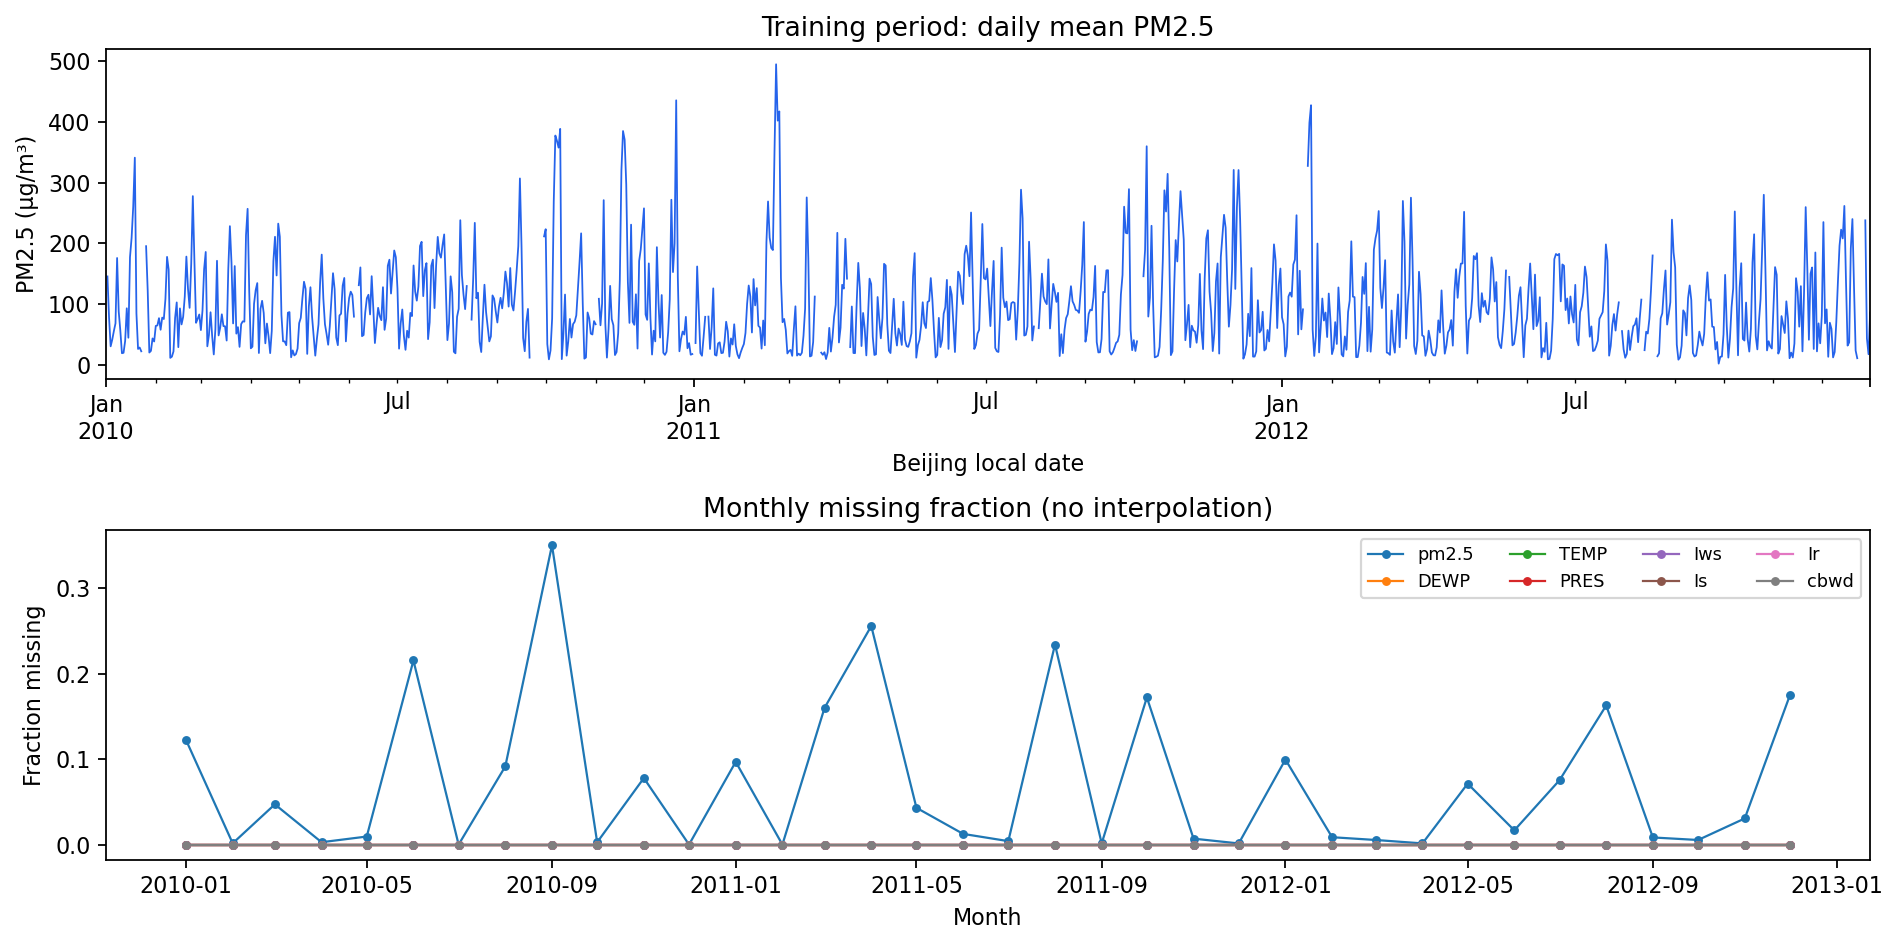

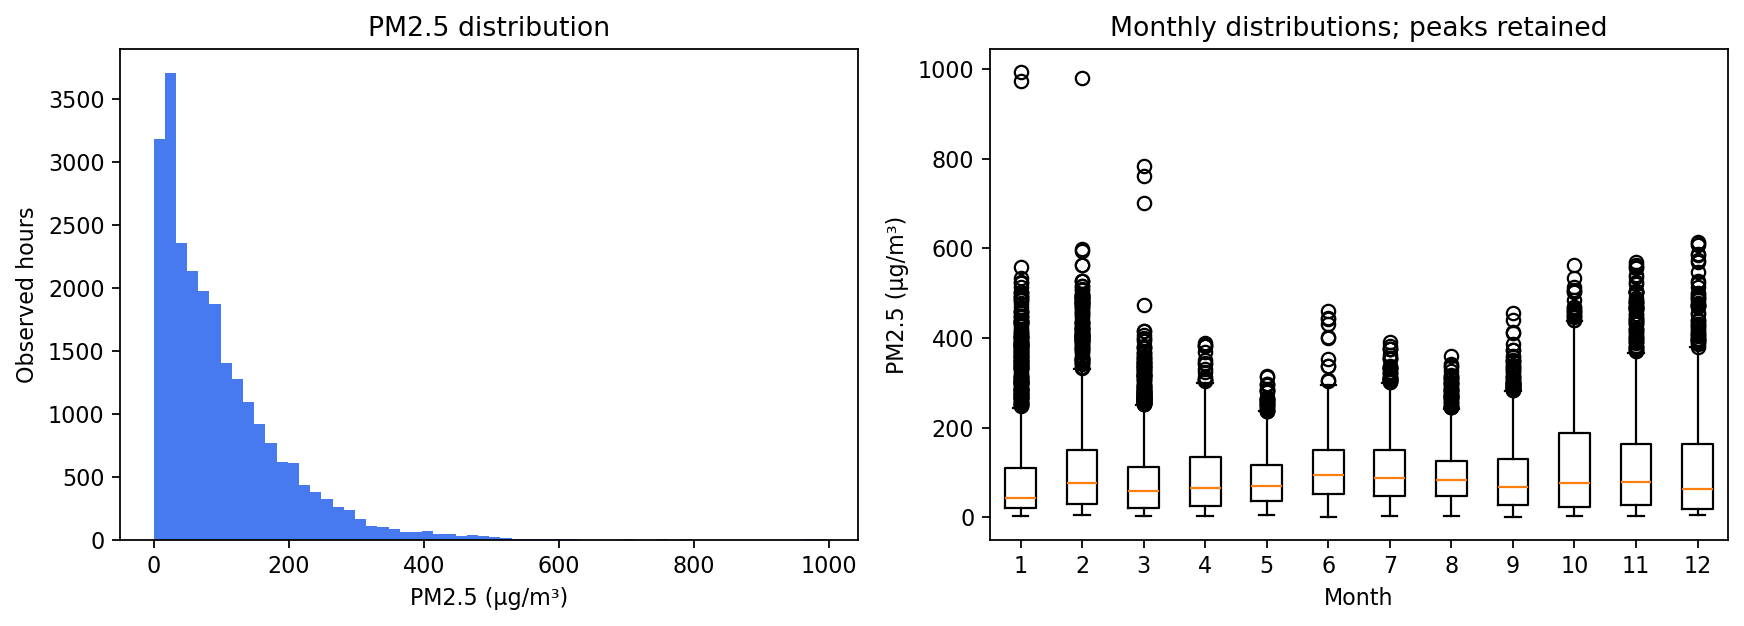

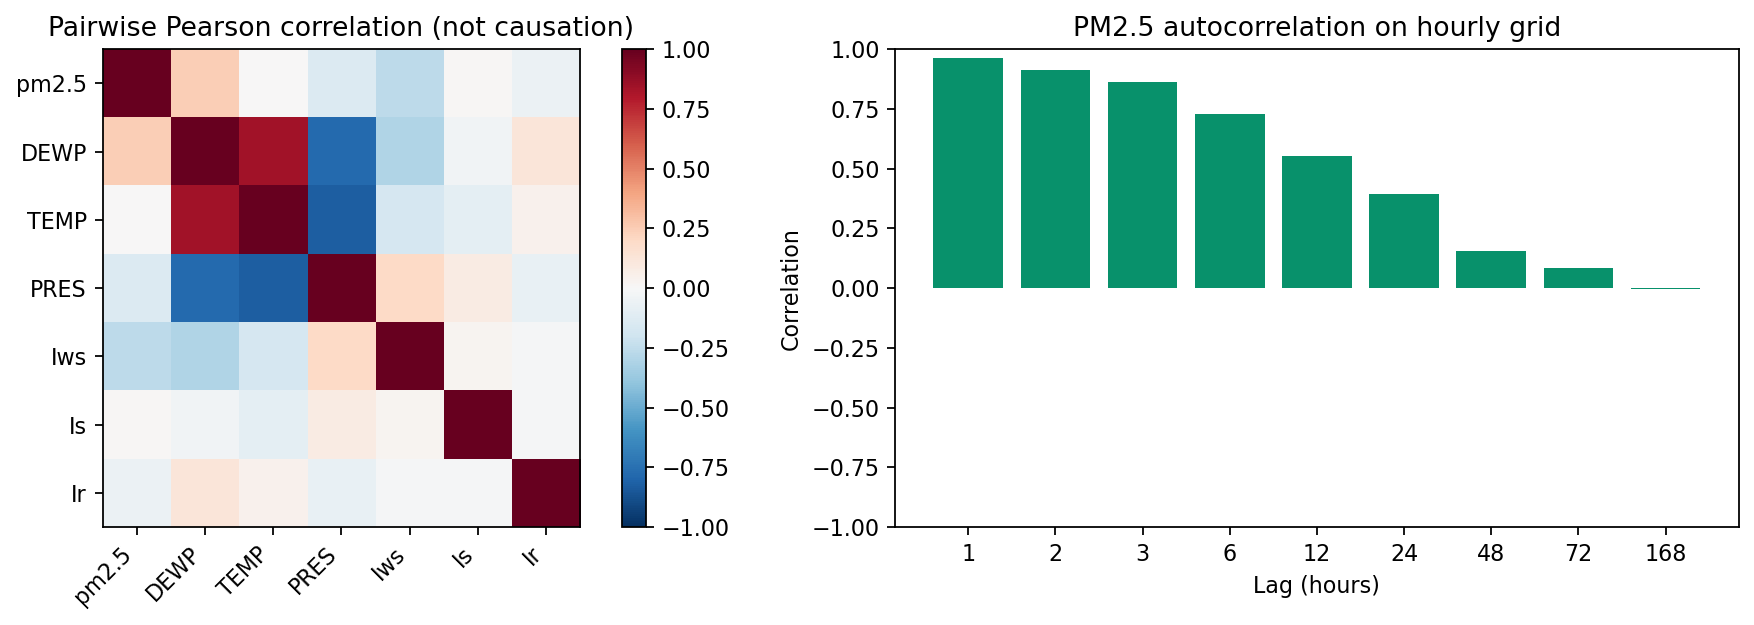

In [6]:
for name in ('timeline_missingness.png', 'distribution_seasonality.png', 'correlation_autocorrelation.png'):
    path = EDA / name
    assert path.is_file()
    if NotebookImage is not None:
        display(NotebookImage(filename=str(path)))
    else:
        print(path.relative_to(ROOT))


In [7]:
data = build_features(dataset.frame, CONFIG)
print('Input features:', len(data.X.columns))
assert len(data.X.columns) == 70
preview = data.X.loc[data.warm, ['pm25_lag_0', 'pm25_lag_24', 'pm25_mean_24', 'weather_TEMP_lag_0']].head().copy()
preview['target_time'] = data.target_time.reindex(preview.index)
preview['observed_future_target'] = data.y.reindex(preview.index)
display(preview.join(data.baselines))
print('Lag zero is observed at issuance; the label is one hour later.')


Input features: 70
                     pm25_lag_0  pm25_lag_24  pm25_mean_24  weather_TEMP_lag_0         target_time  observed_future_target  persistence  seasonal_naive
origin_time                                                                                                                                            
2010-01-08 00:00:00       210.0        127.0     72.458333               -17.0 2010-01-08 01:00:00                   195.0        210.0           130.0
2010-01-08 01:00:00       195.0        130.0     75.166667               -16.0 2010-01-08 02:00:00                   275.0        195.0            43.0
2010-01-08 02:00:00       275.0         43.0     84.833333               -16.0 2010-01-08 03:00:00                   164.0        275.0            37.0
2010-01-08 03:00:00       164.0         37.0     90.125000               -15.0 2010-01-08 04:00:00                   110.0        164.0            30.0
2010-01-08 04:00:00       110.0         30.0     93.458333           

In [8]:
selection = json.loads((RUN / 'selection.json').read_text())
assert selection['holdout_used_for_selection'] is False
print('Settings selected on 2013 only:', selection['selected'])
display(pd.read_csv(RUN / 'validation_candidates.csv'))


Settings selected on 2013 only: {'xgboost': {'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.05, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.9, 'reg_lambda': 5.0}, 'ridge': {'alpha': 10.0}}
     model  candidate                                                                                                                                           parameters  validation_rmse  validation_mae     n
0  xgboost          1    {"colsample_bytree": 0.9, "learning_rate": 0.05, "max_depth": 3, "min_child_weight": 5, "n_estimators": 300, "reg_lambda": 5.0, "subsample": 0.8}        26.772322       13.397421  8563
1  xgboost          2   {"colsample_bytree": 0.9, "learning_rate": 0.03, "max_depth": 4, "min_child_weight": 5, "n_estimators": 500, "reg_lambda": 10.0, "subsample": 0.8}        26.801011       13.250287  8563
2  xgboost          3  {"colsample_bytree": 0.8, "learning_rate": 0.04, "max_depth": 5, "min_child_weight": 10, "n_estimators": 350, "reg_lambda": 10.0, 

In [9]:
predictions = pd.read_csv(RUN / 'predictions.csv', parse_dates=['origin_time', 'target_time'], float_precision='round_trip')
assert not predictions.duplicated(['phase', 'model', 'origin_time']).any()
assert (predictions.target_time - predictions.origin_time).dt.total_seconds().eq(3600).all()
for phase, period in predictions.groupby('phase'):
    reference = None
    for name, group in period.groupby('model'):
        aligned = group.sort_values('origin_time').set_index('origin_time')[['target_time', 'actual', 'fold']]
        if reference is None:
            reference = aligned
        else:
            pd.testing.assert_frame_equal(reference, aligned)
metrics = pd.read_csv(RUN / 'metrics.csv')
pd.testing.assert_frame_equal(score_predictions(predictions), metrics, check_exact=False, rtol=1e-10)
display(metrics)
print('Metrics recomputed on identical observed targets; no percentage accuracy is inferred from R².')


        phase           model     n        mae        rmse        r2      bias
0     holdout     persistence  8531  11.926386   22.033489  0.944221  0.009612
1     holdout           ridge  8531  11.825318   21.062610  0.949028  0.218345
2     holdout  seasonal_naive  8531  67.295745   98.754410 -0.120523  0.239831
3     holdout         xgboost  8531  11.832610   21.087813  0.948906  0.719481
4  validation     persistence  8563  13.183697   24.869582  0.935790  0.032232
5  validation           ridge  8563  13.141397   23.808931  0.941150 -0.097579
6  validation  seasonal_naive  8563  76.079178  110.183097 -0.260358  0.122387
7  validation         xgboost  8563  13.397421   26.772322  0.925589 -0.343725
Metrics recomputed on identical observed targets; no percentage accuracy is inferred from R².


In [10]:
folds = pd.DataFrame(json.loads((RUN / 'fold_audit.json').read_text()))
assert (pd.to_datetime(folds.latest_training_target) <= pd.to_datetime(folds.fit_time)).all()
display(folds[['fold', 'training_rows', 'common_evaluation_rows', 'coverage_fraction', 'latest_training_target', 'fit_time']])
display(pd.read_csv(RUN / 'fold_metrics.csv'))


            fold  training_rows  common_evaluation_rows  coverage_fraction latest_training_target             fit_time
0  validation_01          24273                    2127           0.984722    2012-12-31 23:00:00  2012-12-31 23:00:00
1  validation_02          26422                    2129           0.974817    2013-03-31 23:00:00  2013-03-31 23:00:00
2  validation_03          28582                    2161           0.978714    2013-06-30 23:00:00  2013-06-30 23:00:00
3  validation_04          30771                    2146           0.971920    2013-09-30 23:00:00  2013-09-30 23:00:00
4     holdout_01          32951                    2132           0.987037    2013-12-31 23:00:00  2013-12-31 23:00:00
5     holdout_02          35100                    2133           0.976648    2014-03-31 23:00:00  2014-03-31 23:00:00
6     holdout_03          37262                    2153           0.975091    2014-06-30 23:00:00  2014-06-30 23:00:00
7     holdout_04          39447                 

artifacts/phase1/figures/model_comparison.png
artifacts/phase1/figures/forecast_last_week.png
artifacts/phase1/figures/residual_diagnostics.png


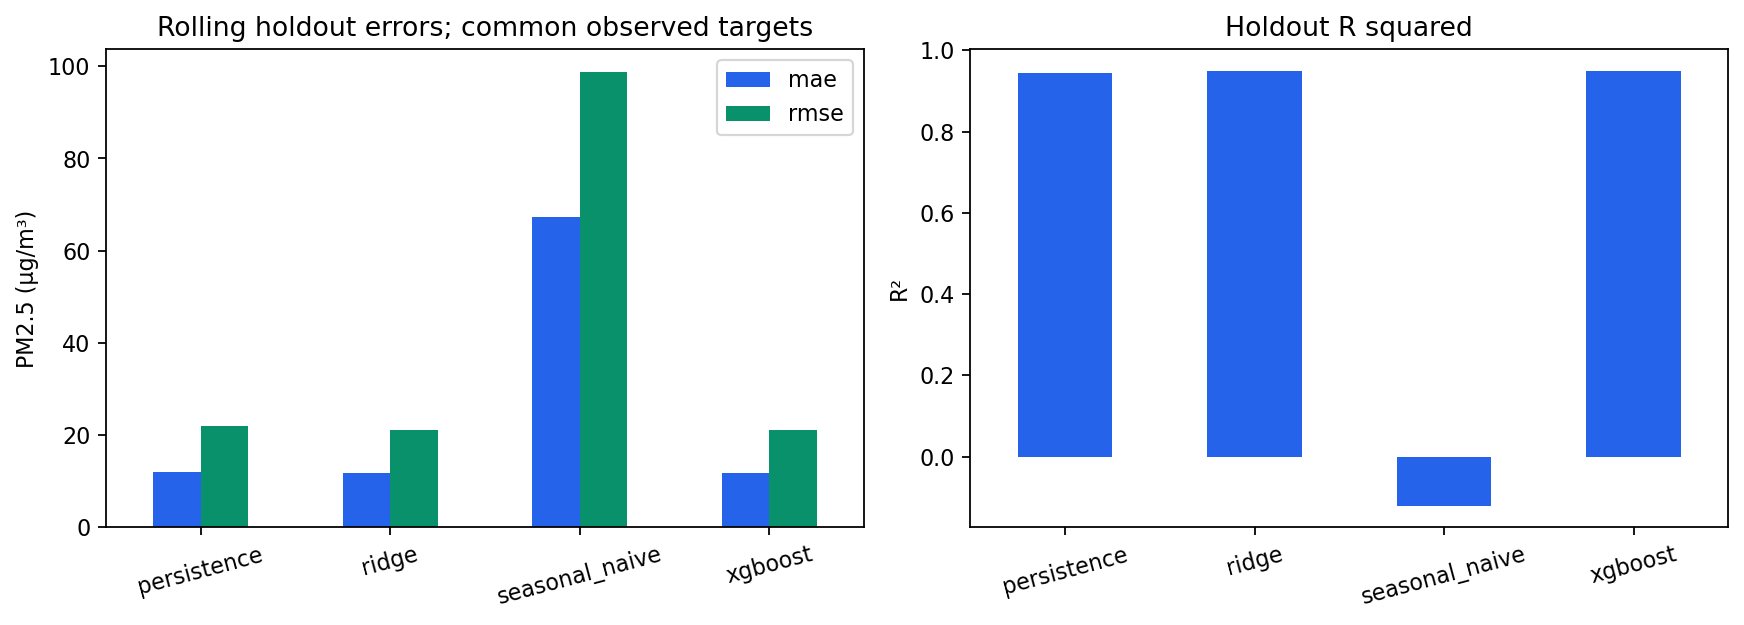

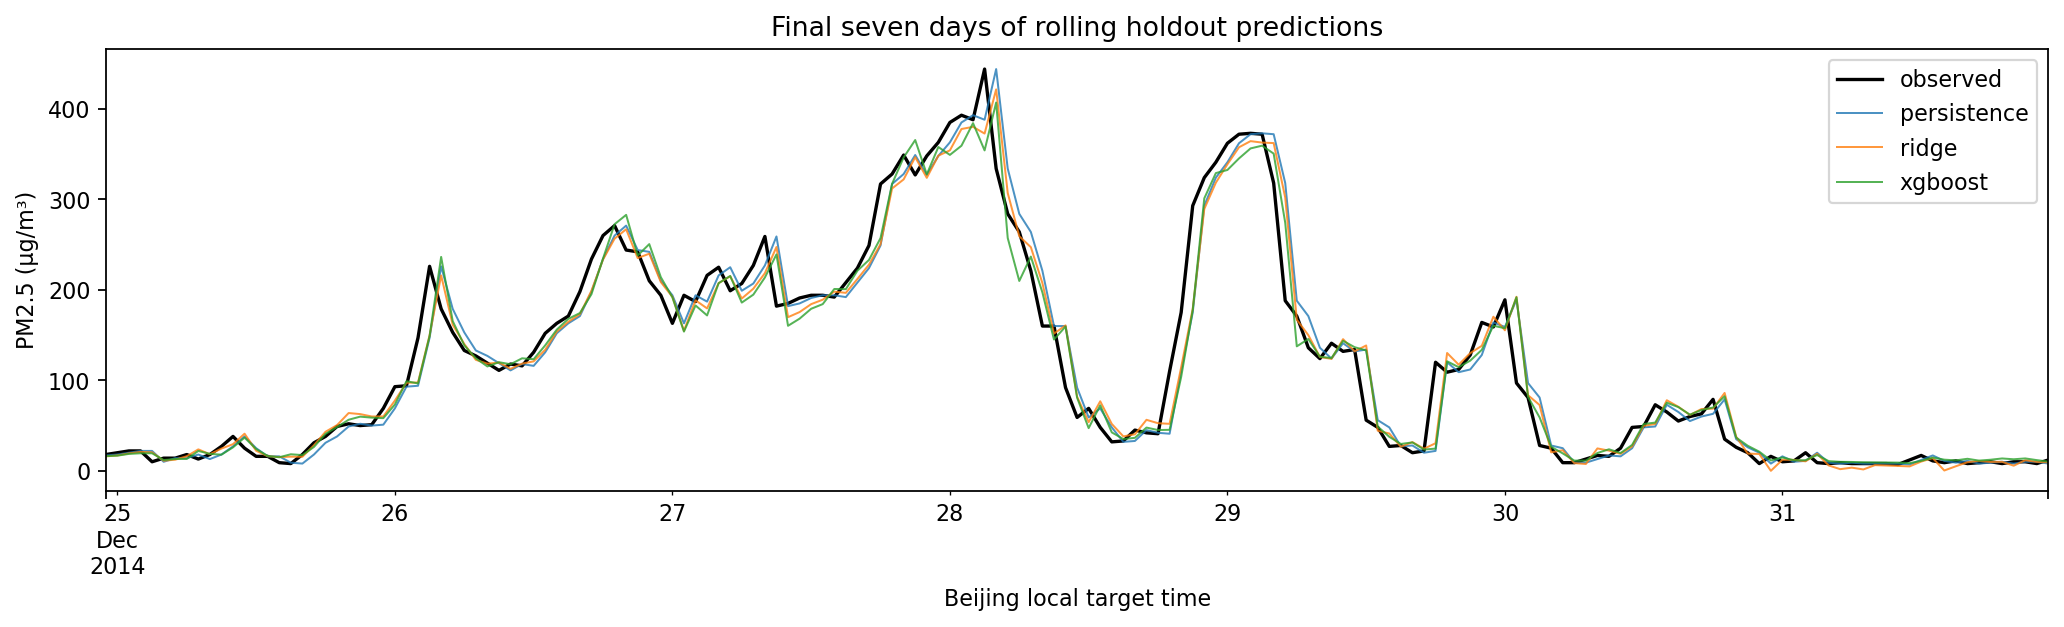

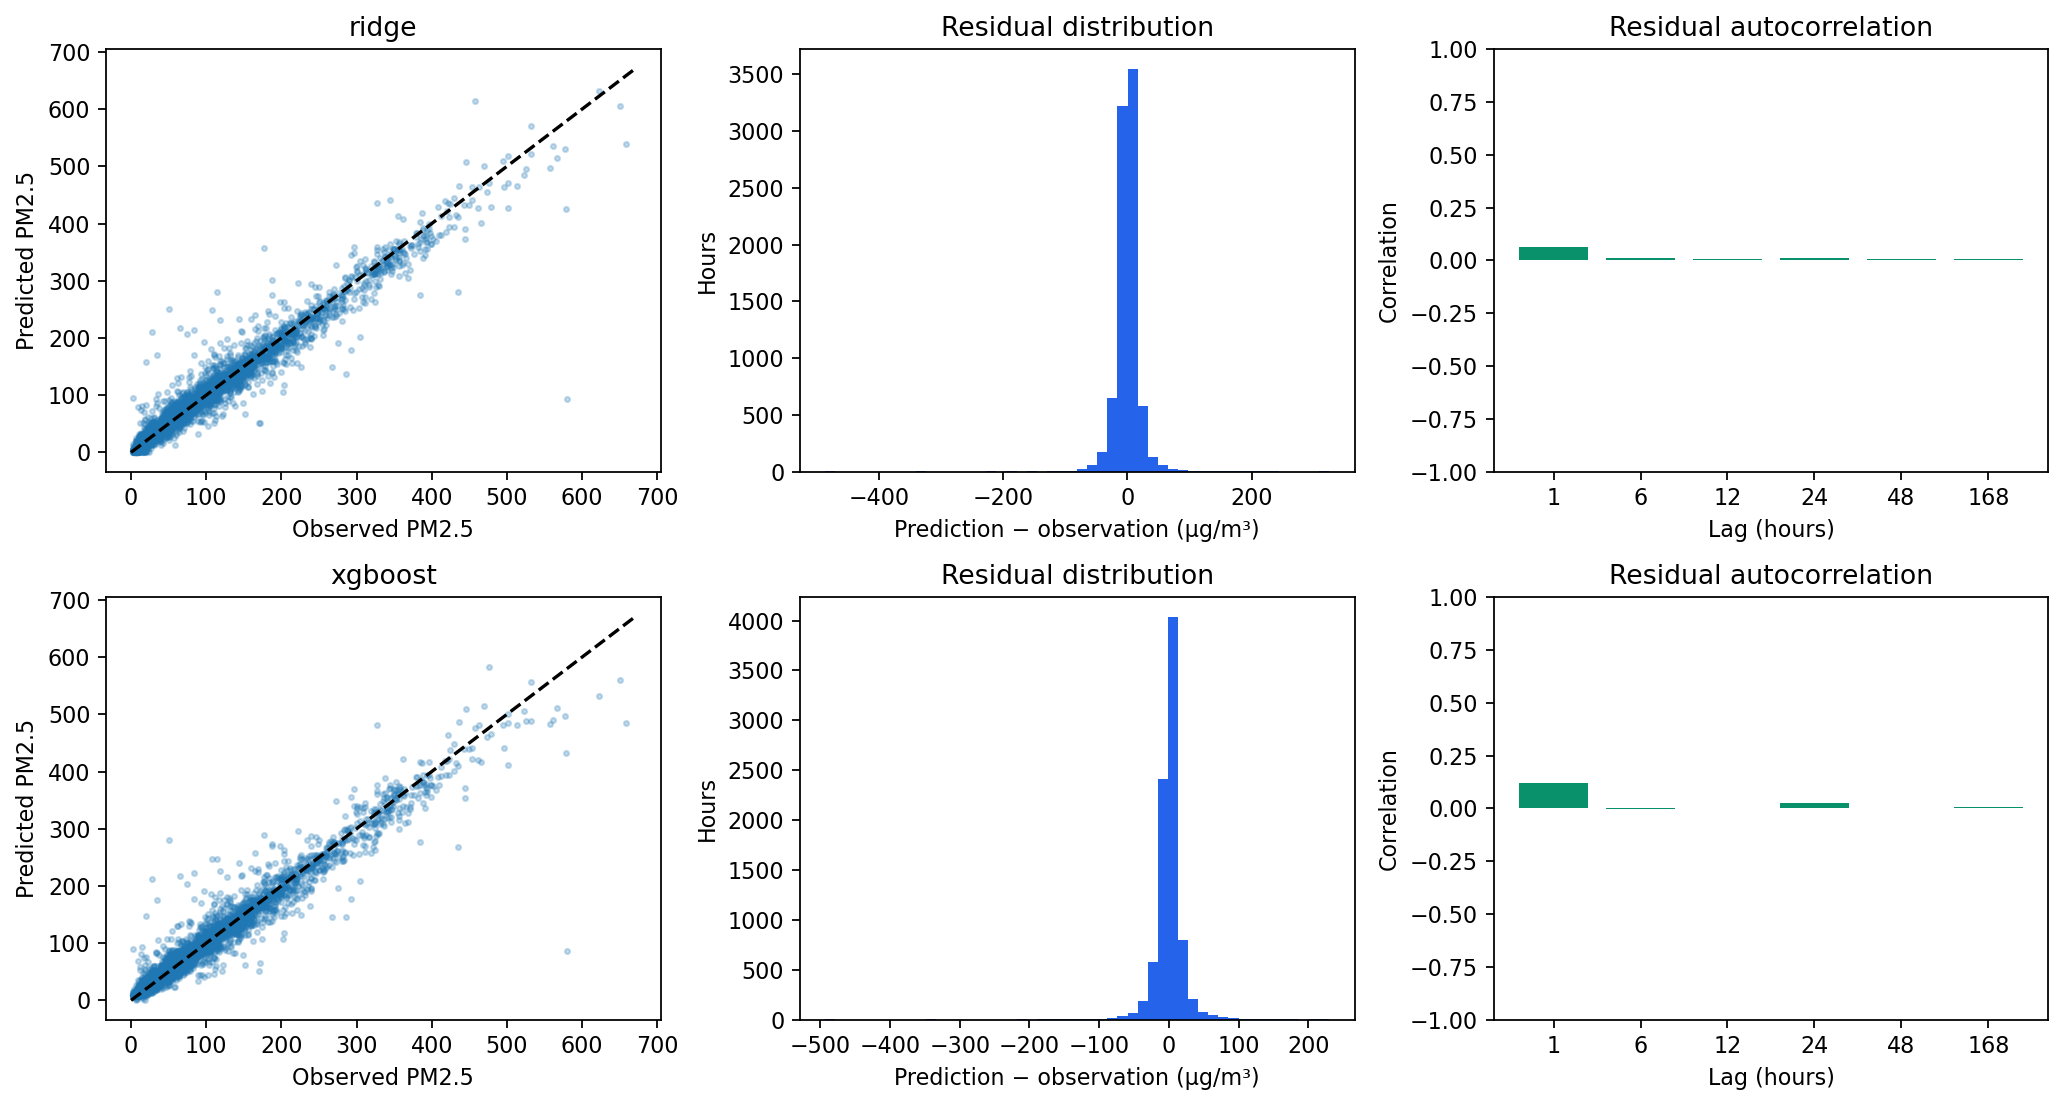

In [11]:
for name in ('model_comparison.png', 'forecast_last_week.png', 'residual_diagnostics.png'):
    path = RUN / 'figures' / name
    assert path.is_file()
    if NotebookImage is not None:
        display(NotebookImage(filename=str(path)))
    else:
        print(path.relative_to(ROOT))


In [12]:
print('Peak threshold from initial training:', manifest['training_p90_pm25'], 'µg/m³')
display(pd.read_csv(RUN / 'errors_by_pollution_regime.csv'))
display(pd.read_csv(RUN / 'validation_ablation.csv'))
print((RUN / 'RESULTS.md').read_text())


Peak threshold from initial training: 218.0 µg/m³
            model    pollution_regime     n         mae        rmse        r2        bias
0     persistence  above_training_p90   865   23.113295   38.556512  0.775035   -5.534104
1     persistence  below_training_p90  7666   10.664101   19.300550  0.873240    0.635142
2           ridge  above_training_p90   865   23.620651   38.521632  0.775442  -13.313277
3           ridge  below_training_p90  7666   10.494382   18.062456  0.888981    1.745197
4  seasonal_naive  above_training_p90   865  124.030058  152.969459 -2.541020 -100.952601
5  seasonal_naive  below_training_p90  7666   60.894078   90.623048 -1.794598   11.657970
6         xgboost  above_training_p90   865   24.408271   39.958806  0.758374  -11.912336
7         xgboost  below_training_p90  7666   10.413625   17.740004  0.892910    2.144804
  feature_set       phase    model     n        mae       rmse        r2      bias
0   lags_only  validation  xgboost  8563  13.677527  27.5

In [13]:
for name in ('xgboost', 'ridge'):
    result = predict_latest(RUN / (name + '.joblib'), DATA)
    assert np.isfinite(result['pm25_ug_m3'])
    print(json.dumps(result, indent=2))
RUN_TESTS = True
if RUN_TESTS:
    tests = [str(ROOT / 'tests' / name) for name in (
        'test_forecasting.py', 'test_data_and_integration.py', 'test_eda_notes.py', 'test_xgboost_optional.py')]
    checked = subprocess.run([sys.executable, '-m', 'pytest', '-q', '-W', 'error::DeprecationWarning', *tests],
                             cwd=ROOT, check=True, capture_output=True, text=True)
    print(checked.stdout)


{
  "model": "xgboost",
  "origin_time": "2014-12-31 23:00:00",
  "target_time": "2015-01-01 00:00:00",
  "horizon_hours": 1,
  "pm25_ug_m3": 11.92273235321045,
  "latest_pm25_missing": false,
  "source": "uci381_user_supplied"
}
{
  "model": "ridge",
  "origin_time": "2014-12-31 23:00:00",
  "target_time": "2015-01-01 00:00:00",
  "horizon_hours": 1,
  "pm25_ug_m3": 13.639784709097256,
  "latest_pm25_missing": false,
  "source": "uci381_user_supplied"
}
........................................                                 [100%]
40 passed in 5.54s



In [14]:
# Export only the verified source snapshot, this run and attributed data.
EXPORT = ROOT / 'dist/phase1_notebook_outputs.zip'
EXPORT.parent.mkdir(exist_ok=True)
with zipfile.ZipFile(EXPORT, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    with zipfile.ZipFile(io.BytesIO(snapshot)) as source:
        for name in source.namelist():
            archive.writestr(name, source.read(name))
    for path in (DATA, DATA.with_suffix('.provenance.json')):
        if path.exists():
            archive.write(path, path.relative_to(ROOT).as_posix())
    for path in sorted(RUN.rglob('*')):
        if path.is_file() and path.suffix in {'.csv', '.json', '.md', '.png', '.pdf', '.tex', '.joblib', '.gz'}:
            archive.write(path, 'artifacts/phase1/' + path.relative_to(RUN).as_posix())
print('Source, measured results, saved models and attributed dataset exported:', EXPORT.relative_to(ROOT))
print('Historical Beijing results do not establish current or other-city accuracy. No AQI is calculated.')


Source, measured results, saved models and attributed dataset exported: dist/phase1_notebook_outputs.zip
Historical Beijing results do not establish current or other-city accuracy. No AQI is calculated.


Dataset: Chen (2015), UCI Beijing PM2.5, DOI [10.24432/C5JS49](https://doi.org/10.24432/C5JS49), CC BY 4.0. The project report and presentation provide interpretation and limitations.